importing the libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

Importing the dataset : https://raw.githubusercontent.com/mk-gurucharan/Regression/master/IceCreamData.csv

In [ ]:
df=pd.read_csv('https://raw.githubusercontent.com/mk-gurucharan/Regression/master/IceCreamData.csv')

In [ ]:
df.head()

,Temperature,Revenue
0,24.566884,534.799028
1,26.005191,625.190122
2,27.790554,660.632289
3,20.595335,487.706960
4,11.503498,316.240194


EDA -> Exploratory Data Analysis

In [ ]:
df.head()


,Temperature,Revenue
0,24.566884,534.799028
1,26.005191,625.190122
2,27.790554,660.632289
3,20.595335,487.706960
4,11.503498,316.240194


In [ ]:
df.tail()

,Temperature,Revenue
495,22.274899,524.746364
496,32.893092,755.818399
497,12.588157,306.090719
498,22.362402,566.217304
499,28.957736,655.660388


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Temperature  500 non-null    float64
 1   Revenue      500 non-null    float64
dtypes: float64(2)
memory usage: 7.9 KB


In [ ]:
df.describe()

,Temperature,Revenue
count,500.000000,500.000000
mean,22.232225,521.570777
std,8.096388,175.404751
min,0.000000,10.000000
25%,17.122258,405.558681
50%,22.392791,529.368565
75%,27.740674,642.257922
max,45.000000,1000.000000


Assigning features and target

In [ ]:
X=np.array(df.Temperature)
Y=np.array(df.Revenue)

Splitting the data

In [ ]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=25,shuffle=True)

Choosing the model

In [ ]:
Random=RandomForestRegressor(n_estimators=10,random_state=0)

Training the model

In [ ]:
Random.fit(X_train.reshape(-1,1),Y_train.reshape(-1,1))

c:\Users\arunk\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:1152: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


RandomForestRegressor(n_estimators=10, random_state=0)

Testing the model

In [ ]:
Y_pred=Random.predict(X_test.reshape(-1,1))

In [ ]:
Y_pred

array([430.57044703, 426.26077776, 729.68592322, 636.80064947,
       462.39956138, 214.32099441, 438.56609549, 685.02309088,
       389.34349083, 491.20560002, 458.96461849, 569.56400263,
       701.46392542, 308.12560689, 240.86211521, 528.92955821,
       797.37040464, 297.77955779, 782.2504971 , 429.9368556 ,
       402.39023794, 215.97945188, 468.97514142, 700.56399101,
       553.64658387, 545.90064951, 652.78269659, 611.43757063,
       838.95235881, 401.68538628, 158.39533988, 285.33029002,
       765.29452478, 546.10386759, 659.3384728 , 612.3177422 ,
       493.99226912, 209.19522726, 406.70547459, 902.38806457,
       595.08715076, 543.54125001, 458.37091357, 524.1625845 ,
       467.05507862, 328.58566941, 489.23127256, 799.68885175,
       683.6713729 , 137.58135621, 382.85424538, 522.03305751,
       401.41655731, 799.68885175, 472.27554758, 603.13283059,
       467.05507862, 393.86809265, 314.17753304, 269.88388188,
       380.47832082, 317.2246409 , 693.37873626, 394.62

In [ ]:
ans=pd.DataFrame({'Actual Data':Y_test,'Predicted Data':Y_pred})

In [ ]:
ans.head()

,Actual Data,Predicted Data
0,443.113603,430.570447
1,513.804382,426.260778
2,740.935685,729.685923
3,632.901914,636.800649
4,474.832244,462.399561


In [ ]:
Random.score(X_test.reshape(-1,1),Y_test)

0.9660999195821166

In [ ]:
mean_squared_error(Y_test,Y_pred)

942.6413628316312

In [ ]:
mean_absolute_error(Y_test,Y_pred)

24.24288109589999

In [ ]:
r2_score(Y_test,Y_pred)

0.9660999195821166

In [ ]:
Random.predict([[28.95]])

array([668.45136488])

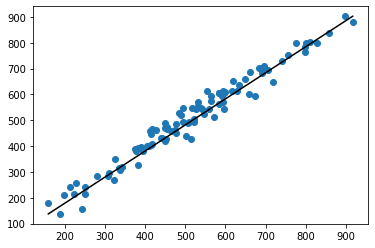

In [ ]:
plt.scatter(Y_test,Y_pred)
plt.plot([Y_test.min(),Y_test.max()],[Y_pred.min(),Y_pred.max()],color='black')

Text(0, 0.5, 'Revenue')

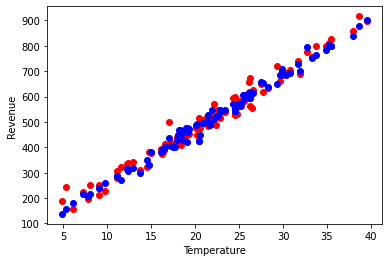

In [ ]:
plt.scatter(X_test,Y_test,color='red')
plt.scatter(X_test,Y_pred,color='blue')
plt.xlabel('Temperature')
plt.ylabel('Revenue')

<Axes: >

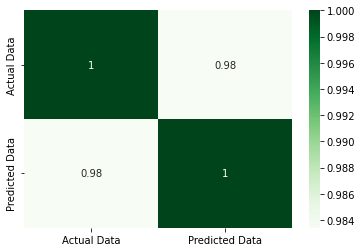

In [ ]:
sns.heatmap(ans.corr(),annot=True,cmap='Greens')